# CDS-prompted benchmark — main figure (2×2)

**Story:** competent → shallow → insensitive → harmful.

| panel | claim |
|---|---|
| **A** | PROK generates **species-specific** regulatory sequence (6-mer composition, correct vs wrong species token) |
| **B** | It reproduces the **natural Shine–Dalgarno** profile — it *can* write an RBS |
| **C** | Across the full 200 bp the base distribution is **unchanged** by shuffling or swapping the CDS |
| **D** | **Removing** the CDS *improves* SD placement — the conditioning signal actively hurts |

Two-stage by design: `fig_stats.py` computes every statistic on the cluster (where the
generations live) and caches to `cds_fig_stats.npz`; this notebook renders from the
cache, so it runs anywhere with only the 1.8 MB `.npz` present.

```
on the cluster :  python fig_stats.py --out cds_fig_stats.npz
locally        :  run this notebook
```

**Not in this repository.** `cds_fig_stats.npz` is the full-population cache and is
built from the raw generations, which are tens of gigabytes and stay on the cluster.
What is released instead is the held-out test-set cache,
`results/cds_prompted/cds_fig_stats_testset.npz`, which carries conditions C0, C2 and
C3 only. **To reproduce the released figure without the cluster, run
`python code/figure_3_cds_conditioning/render_fig_testset.py`** — it reads the shipped
cache and writes `figures/cds_prompted_main.pdf`. This notebook additionally needs
C1, C4, C5 and C6, so it will not run from the shipped cache alone; the cell below
says so rather than failing with a bare `FileNotFoundError`.

**Aggregation rule, applied everywhere:** within a gene, the 20 generations give a
base distribution at each position; genes are only combined afterwards. Generations
are never pooled across genes — that would be pseudoreplication.

In [1]:
import csv, os
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D

HERE = os.path.dirname(os.path.abspath('__file__')) if '__file__' in dir() else os.getcwd()
ROOT = os.path.abspath(os.path.join(HERE, '..', '..'))
STATS = os.path.join(HERE, 'cds_fig_stats.npz')
RESULTS, FIGURES = os.path.join(ROOT, 'results'), os.path.join(ROOT, 'figures')
SHIPPED = os.path.join(RESULTS, 'cds_prompted', 'cds_fig_stats_testset.npz')
os.makedirs(FIGURES, exist_ok=True)

if not os.path.exists(STATS):
    raise FileNotFoundError(
        f"{STATS} is not in this repository.\n"
        "It is the full-population cache, built by fig_stats.py from the raw\n"
        "generations, which stay on the cluster. The released cache is\n"
        f"  {SHIPPED}\n"
        "but it carries conditions C0, C2 and C3 only, while this notebook also\n"
        "needs C1, C4, C5 and C6.\n\n"
        "To reproduce the released figure without the cluster, run instead:\n"
        "  python code/figure_3_cds_conditioning/render_fig_testset.py"
    )

D = np.load(STATS, allow_pickle=True)
print(f'{len(D.files)} cached arrays')

# ---- publication style: thick axes, real fonts, editable vector text ----
mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9,
    'axes.linewidth': 1.6, 'axes.labelsize': 9.5, 'axes.titlesize': 10,
    'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'xtick.major.size': 4.5, 'ytick.major.size': 4.5,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.frameon': False, 'legend.fontsize': 8,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'axes.spines.top': False, 'axes.spines.right': False,
})

BASE_C = {'A': '#2E7D32', 'C': '#1565C0', 'G': '#EF9A00', 'T': '#C62828'}
SPN = {'ecoli': 'E. coli', 'bsubtilis': 'B. subtilis'}

def ital(sp):
    """Species name in maths italic (f-strings cannot contain backslashes)."""
    return '$\\it{' + SPN[sp].replace(' ', '\\ ') + '}$'
C_OK, C_BAD, C_GREY = '#2166AC', '#B2182B', '#7A7A7A'

def panel_tag(ax, letter, dx=-0.16, dy=1.06):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=15,
            fontweight='bold', va='top', ha='left')

151 cached arrays


## Panel A — species-specific composition

Mean 6-mer frequency of generated upstreams vs natural upstreams. **Correct** = generated
with that species' own token; **Wrong** = the other species' token (negative control).
Points on the diagonal mean the model reproduces natural composition.

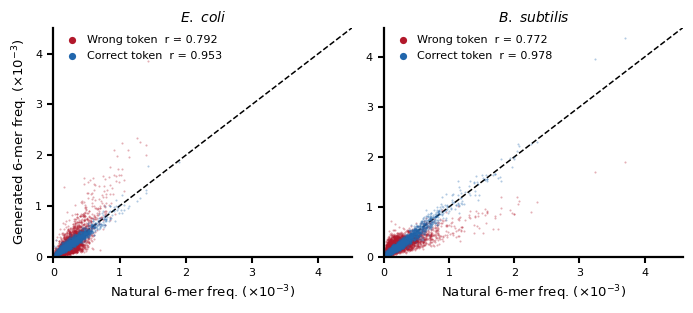

In [2]:
def draw_A(ax, sp):
    """Log-log: 6-mer frequencies span three decades, so a linear axis puts 99%
    of the 4,096 points in one corner. Identity line = perfect agreement."""
    nat = D[f'A_{sp}_nat']
    lo = min(D[f'A_{sp}_nat'].min(), D[f'A_{sp}_correct'].min(),
             D[f'A_{sp}_wrong'].min()) * 0.7
    hi = max(D[f'A_{sp}_nat'].max(), D[f'A_{sp}_correct'].max(),
             D[f'A_{sp}_wrong'].max()) * 1.4
    ax.plot([lo, hi], [lo, hi], color='k', lw=1.1, ls='--', zorder=1)
    for kind, col, lab in (('wrong', C_BAD, 'Wrong token'), ('correct', C_OK, 'Correct token')):
        gen = D[f'A_{sp}_{kind}']
        r = float(D[f'A_{sp}_{kind}_r'])
        ax.scatter(nat, gen, s=5.5, alpha=0.45, linewidths=0, color=col,
                   label=f'{lab}  r = {r:.3f}', rasterized=True,
                   zorder=3 if kind == 'correct' else 2)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel('Natural 6-mer frequency')
    ax.set_title(ital(sp), pad=4)
    leg = ax.legend(loc='upper left', handletextpad=0.3, borderpad=0.2, markerscale=2.6)
    for h in leg.legend_handles:
        h.set_alpha(1)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.2))
for ax, sp in zip(axs, ['ecoli', 'bsubtilis']):
    draw_A(ax, sp)
axs[0].set_ylabel('Generated 6-mer frequency')
plt.tight_layout(); plt.show()


## Panel B — the Shine–Dalgarno is reproduced

Per-base probability over the 20 bp before the start codon. **Natural** is the population
frequency across genes (one real sequence per gene). **Generated** is the mean across genes
of each gene's within-gene distribution over its 20 generations; shading is ±1 SD across genes.

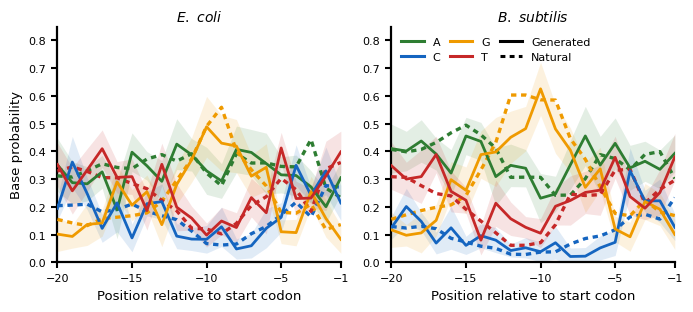

In [3]:
def draw_B(ax, sp, show_ylabel=False):
    x = np.arange(-20, 0)
    nat, mu, sd = D[f'{sp}_natural'][180:], D[f'{sp}_C0_mean'][180:], D[f'{sp}_C0_sd'][180:]
    for i, b in enumerate('ACGT'):
        ax.plot(x, nat[:, i], color=BASE_C[b], lw=2.4, ls=(0, (1.6, 1.4)), zorder=3)
        ax.plot(x, mu[:, i], color=BASE_C[b], lw=2.0, zorder=4)
        ax.fill_between(x, mu[:, i] - sd[:, i], mu[:, i] + sd[:, i],
                        color=BASE_C[b], alpha=0.13, lw=0, zorder=1)
    ax.set_xlim(-20, -1); ax.set_ylim(0, 0.85)
    ax.set_xticks([-20, -15, -10, -5, -1])
    ax.set_xlabel('Position relative to start codon')
    ax.set_title(ital(sp), pad=4)
    if show_ylabel:
        ax.set_ylabel('Base probability')

fig, axs = plt.subplots(1, 2, figsize=(7, 3.2))
for i, sp in enumerate(['ecoli', 'bsubtilis']):
    draw_B(axs[i], sp, show_ylabel=(i == 0))
h = [Line2D([], [], color=BASE_C[b], lw=2.2, label=b) for b in 'ACGT']
h += [Line2D([], [], color='k', lw=2.2, label='Generated'),
      Line2D([], [], color='k', lw=2.2, ls=(0, (1.6, 1.4)), label='Natural')]
axs[1].legend(handles=h, ncol=3, loc='upper left', columnspacing=0.9)
plt.tight_layout(); plt.show()

## Panel C — the CDS does not move the distribution

The same per-base probability across the **full 200 bp**, under three prompts:
the real CDS (**C0**), a codon-shuffled CDS (**C2**), and a different gene's CDS (**C3**).
Line = mean across genes of the within-gene distribution; shading = ±1 SD across genes.

The three rows are visually identical, so the bottom strip plots the **difference** from C0,
magnified 20×, to show the null is a measurement rather than an absence of plotting.

/var/folders/7x/7scxxbdj6fz3w64qtgzb5pxm0000gn/T/ipykernel_15829/779620469.py:53: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


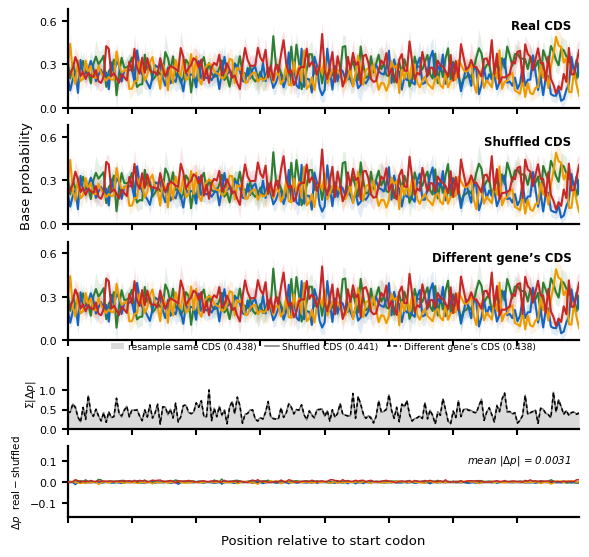

In [4]:
COND_LAB = {'C0': 'Real CDS', 'C2': 'Shuffled CDS', 'C3': 'Different gene\u2019s CDS'}

def draw_C(axes, sp):
    x = np.arange(-200, 0)
    for ax, c in zip(axes[:3], ['C0', 'C2', 'C3']):
        mu, sd = D[f'{sp}_{c}_mean'], D[f'{sp}_{c}_sd']
        for i, b in enumerate('ACGT'):
            ax.plot(x, mu[:, i], color=BASE_C[b], lw=1.5)
            ax.fill_between(x, mu[:, i] - sd[:, i], mu[:, i] + sd[:, i],
                            color=BASE_C[b], alpha=0.12, lw=0)
        ax.set_ylim(0, 0.68); ax.set_xlim(-200, -1)
        ax.set_yticks([0, 0.3, 0.6])
        ax.text(0.985, 0.9, COND_LAB[c], transform=ax.transAxes,
                ha='right', va='top', fontsize=8.5, fontweight='bold')
        ax.set_xticklabels([])
    # summary 1: how far each condition moves the profile, against the
    # resampling null (same CDS, a different 10 decodes)
    axd = axes[3]
    nl = D[f'{sp}_null_diff']
    axd.fill_between(x, 0, nl, color='0.86', lw=0, zorder=1,
                     label=f'resample same CDS ({nl.mean():.3f})')
    for c, col, ls in (('C2', C_GREY, '-'), ('C3', 'k', (0, (2.4, 1.8)))):
        dd = D[f'{sp}_diff_{c}']
        axd.plot(x, dd, color=col, lw=1.1, ls=ls, zorder=3,
                 label=f'{COND_LAB[c]} ({dd.mean():.3f})')
    axd.set_xlim(-200, -1); axd.set_ylim(0, 1.85); axd.set_yticks([0, 0.5, 1.0])
    axd.set_xticklabels([])
    axd.set_ylabel('$\\Sigma|\\Delta p|$', fontsize=7.8, labelpad=1)
    axd.legend(ncol=3, loc='upper center', handlelength=1.5, fontsize=6.6,
               columnspacing=0.9, borderpad=0.15, handletextpad=0.4,
               bbox_to_anchor=(0.5, 1.30))

    # summary 2: the signed per-base difference, real CDS minus shuffled CDS.
    # If the CDS mattered anywhere, a base would depart from zero there.
    axr = axes[4]
    dif = D[f'{sp}_C2_mean'] - D[f'{sp}_C0_mean']
    axr.axhline(0, color='k', lw=1.0, zorder=2)
    for i, b in enumerate('ACGT'):
        axr.plot(x, dif[:, i], color=BASE_C[b], lw=1.1, zorder=3)
    m = np.abs(dif).mean()
    axr.set_xlim(-200, -1); axr.set_ylim(-0.17, 0.17)
    axr.set_yticks([-0.1, 0, 0.1])
    axr.set_xlabel('Position relative to start codon')
    axr.set_ylabel('$\\Delta p$  real\u2009\u2212\u2009shuffled', fontsize=7.4)
    axr.text(0.985, 0.90, f'mean $|\\Delta p|$ = {m:.4f}', transform=axr.transAxes,
             ha='right', va='top', fontsize=7.4, style='italic')

fig, axs = plt.subplots(5, 1, figsize=(6.6, 6.6), sharex=True,
                        gridspec_kw={'height_ratios': [1, 1, 1, 0.72, 0.72],
                                     'hspace': 0.20})
draw_C(list(axs), 'ecoli')
axs[1].set_ylabel('Base probability')
plt.tight_layout(); plt.show()

## Panel D — generated upstreams do not carry per-gene composition

One GC value per gene: the real sequence for natural, the mean of the 20 generations for
the model. Dashed line is that species' natural mean.

**Caption numbers.** Gene-to-gene sd: natural 6.6% / 5.4%, generated 2.3% / 2.4%
(*E. coli* / *B. subtilis*) - the model captures about a third of the natural diversity
and clusters on the species mean. Its spread *within* a single gene is 7.3% / 6.1%,
three times its spread *between* genes, so two generations for one gene differ more in
composition than two different genes do. Sampling noise is removed by
$\mathrm{var}(\bar{x}_{20}) = \mathrm{var}_{\text{gene}} + \mathrm{var}_{\text{within}}/20$;
the gene-independent noise floor is 1.6% / 1.4%, so the residual per-gene signal is real
but weak.


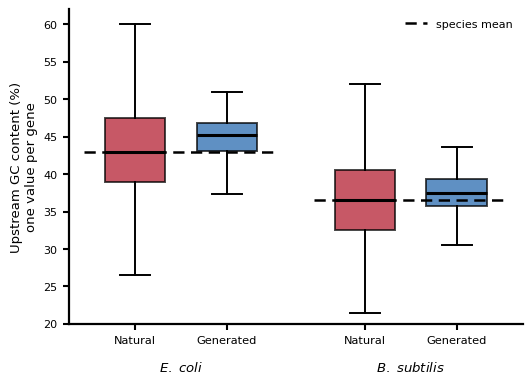

In [5]:
def boot_ci(v, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    m = np.array([rng.choice(v, len(v), replace=True).mean() for _ in range(n)])
    return np.percentile(m, 2.5), np.percentile(m, 97.5)

def draw_D(ax):
    """Per-gene GC of the whole 200 bp upstream. Dashed line = that species'
    natural mean. Numbers and interpretation belong in the caption, not the axes."""
    pos, data, cols = [], [], []
    for gi, sp in enumerate(['ecoli', 'bsubtilis']):
        for bi, (key, col) in enumerate((('nat', '#B2182B'), ('gen', '#2166AC'))):
            pos.append(gi * 2.5 + bi); data.append(100 * D[f'GC_{sp}_{key}']); cols.append(col)
    bp = ax.boxplot(data, positions=pos, widths=0.66, patch_artist=True, showfliers=False,
                    medianprops=dict(color='k', lw=2.2), whiskerprops=dict(lw=1.4),
                    capprops=dict(lw=1.4), boxprops=dict(lw=1.4))
    for patch, col in zip(bp['boxes'], cols):
        patch.set_facecolor(col); patch.set_alpha(0.72)
    # species mean of the natural upstreams
    for gi, sp in enumerate(['ecoli', 'bsubtilis']):
        m = 100 * D[f'GC_{sp}_nat'].mean()
        ax.plot([gi * 2.5 - 0.55, gi * 2.5 + 1.55], [m, m], color='k', lw=1.8,
                ls=(0, (4.5, 2.6)), zorder=5)
    ax.set_xticks(pos)
    ax.set_xticklabels(['Natural', 'Generated'] * 2, fontsize=8.2)
    for gi, sp in enumerate(['ecoli', 'bsubtilis']):
        ax.text(gi * 2.5 + 0.5, -0.115, ital(sp), transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=9.5)
    ax.set_ylabel('Upstream GC content (%)\none value per gene')
    ax.set_ylim(20, 62); ax.set_xlim(-0.72, 4.22)
    h = [Line2D([], [], color='k', lw=1.8, ls=(0, (4.5, 2.6)), label='species mean')]
    ax.legend(handles=h, loc='upper right', fontsize=8)

fig, ax = plt.subplots(figsize=(5.4, 3.9))
draw_D(ax)
plt.tight_layout(); plt.show()

## Assemble the 2×2

wrote cds_prompted_main.{pdf,png} to results/ and figures/


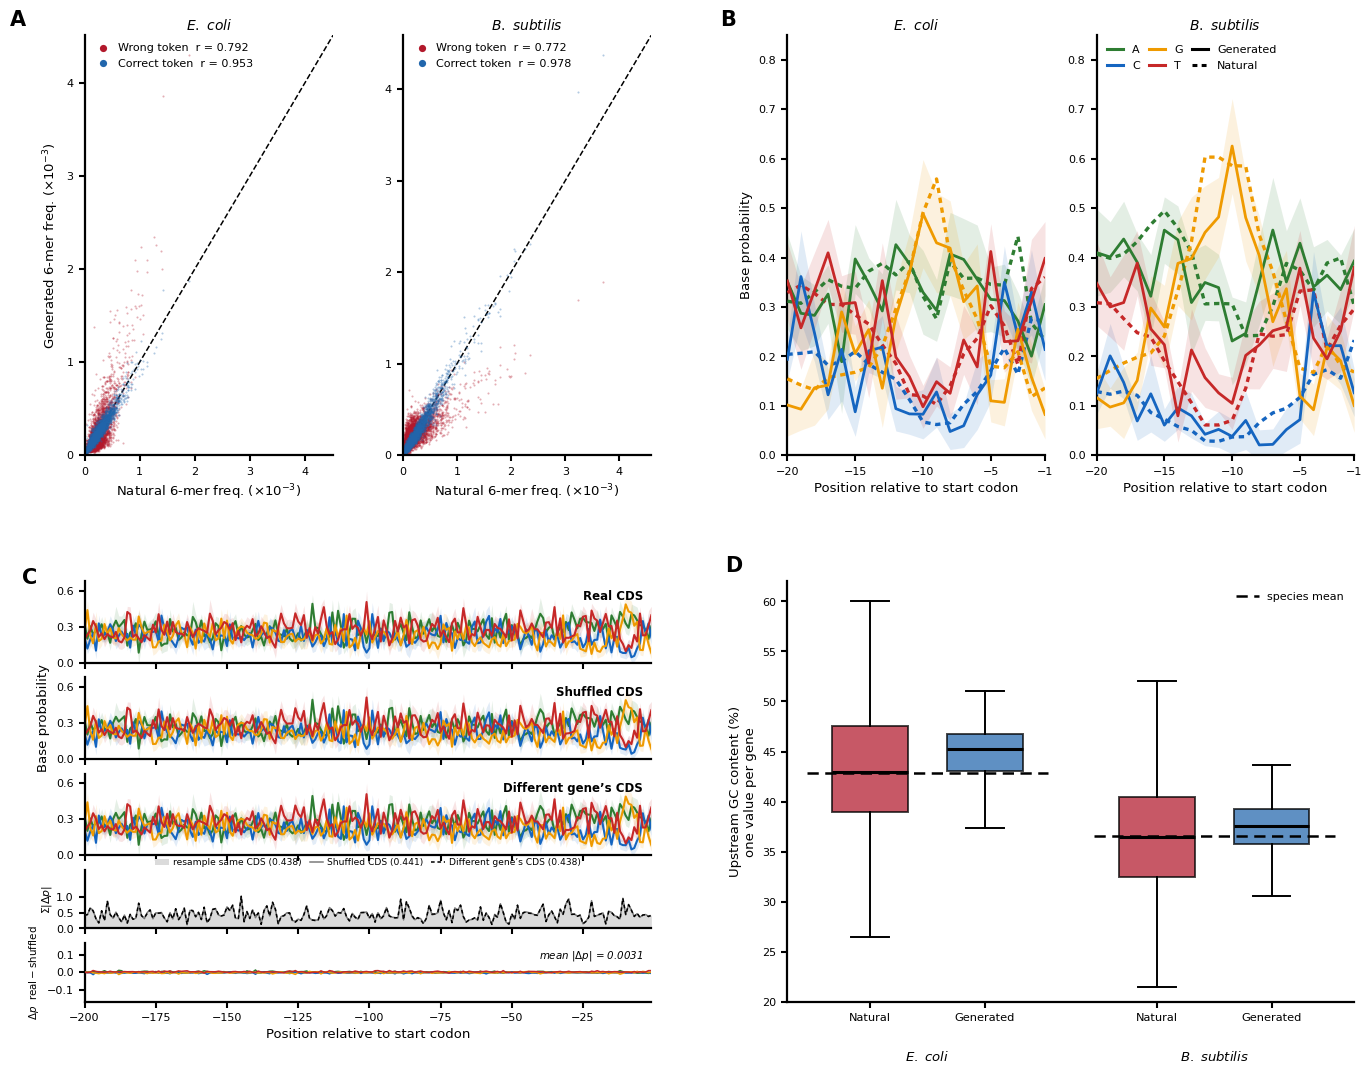

In [6]:
fig = plt.figure(figsize=(13.8, 10.8))
outer = GridSpec(2, 2, figure=fig, hspace=0.30, wspace=0.24,
                 left=0.065, right=0.985, top=0.955, bottom=0.06)

# --- A ---
gA = GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0, 0], wspace=0.28)
aA = [fig.add_subplot(gA[0, i]) for i in range(2)]
for ax, sp in zip(aA, ['ecoli', 'bsubtilis']):
    draw_A(ax, sp)
aA[0].set_ylabel('Generated 6-mer frequency')
panel_tag(aA[0], 'A', dx=-0.30)

# --- B ---
gB = GridSpecFromSubplotSpec(1, 2, subplot_spec=outer[0, 1], wspace=0.20)
aB = [fig.add_subplot(gB[0, i]) for i in range(2)]
for i, sp in enumerate(['ecoli', 'bsubtilis']):
    draw_B(aB[i], sp, show_ylabel=(i == 0))
hB = [Line2D([], [], color=BASE_C[b], lw=2.2, label=b) for b in 'ACGT']
hB += [Line2D([], [], color='k', lw=2.2, label='Generated'),
       Line2D([], [], color='k', lw=2.2, ls=(0, (1.6, 1.4)), label='Natural')]
aB[1].legend(handles=hB, ncol=3, loc='upper left', columnspacing=0.8, handlelength=1.5)
panel_tag(aB[0], 'B', dx=-0.26)

# --- C ---
gC = GridSpecFromSubplotSpec(5, 1, subplot_spec=outer[1, 0],
                             height_ratios=[1, 1, 1, 0.72, 0.72], hspace=0.20)
aC = [fig.add_subplot(gC[i, 0]) for i in range(5)]
draw_C(aC, 'ecoli')
aC[1].set_ylabel('Base probability')
panel_tag(aC[0], 'C', dx=-0.11, dy=1.16)

# --- D ---
aD = fig.add_subplot(outer[1, 1])
draw_D(aD)
panel_tag(aD, 'D', dx=-0.11)

for ext in ('pdf', 'png'):
    for out in (RESULTS, FIGURES):
        fig.savefig(os.path.join(out, f'cds_prompted_main.{ext}'),
                    dpi=400, bbox_inches='tight')
print('wrote cds_prompted_main.{pdf,png} to results/ and figures/')
plt.show()

## KL divergence table

Reported as a table rather than a panel — seven conditions × two species is a
number-dense comparison that a reader parses faster in text.

`KL(C0‖Ci)` is measured **teacher-forced on the real upstream**, so the context is
byte-identical across conditions and any divergence is attributable to the CDS alone.

In [7]:
DESC = {'C0': 'real CDS (reference)', 'C1': 'synonymous codons permuted',
        'C2': 'codon order shuffled', 'C3': 'CDS from another gene',
        'C4': 'no CDS at all', 'C5': 'first 90 nt shuffled (5\u2032 head)',
        'C6': 'nt 90\u2013end shuffled (3\u2032 tail)'}

rows = {}
for sp in ['ecoli', 'bsubtilis']:
    p = os.path.join(ROOT, 'data', 'cds_prompted', 'results', f'm1_{sp}.csv')
    for r in csv.DictReader(open(p)):
        rows.setdefault(r['condition'], {})[sp] = float(r['kl_per_gene_mean'])

hdr = f"| condition | perturbation | KL E. coli | KL B. subtilis |"
print(hdr); print('|---|---|---|---|')
lines = [hdr, '|---|---|---|---|']
for c in ['C1', 'C2', 'C3', 'C4', 'C5', 'C6']:
    l = f"| {c} | {DESC[c]} | {rows[c]['ecoli']:.2f} | {rows[c]['bsubtilis']:.2f} |"
    print(l); lines.append(l)
open(os.path.join(RESULTS, 'cds_prompted', 'kl_table.md'), 'w').write('\n'.join(lines) + '\n')
print('\n[wrote results/cds_prompted/kl_table.md]')
print('\nUnits: bits per gene, summed over the 200 generated positions.')
print('For scale, the mean predictive entropy is ~1.9 bits per position (~380 bits per gene),')
print('so even deleting the CDS entirely (C4) moves the distribution by <1%.')

| condition | perturbation | KL E. coli | KL B. subtilis |
|---|---|---|---|
| C1 | synonymous codons permuted | 0.49 | 0.58 |
| C2 | codon order shuffled | 1.05 | 1.14 |
| C3 | CDS from another gene | 2.05 | 2.17 |
| C4 | no CDS at all | 2.80 | 2.81 |
| C5 | first 90 nt shuffled (5′ head) | 0.02 | 0.03 |
| C6 | nt 90–end shuffled (3′ tail) | 0.96 | 1.04 |

[wrote results/cds_prompted/kl_table.md]

Units: bits per gene, summed over the 200 generated positions.
For scale, the mean predictive entropy is ~1.9 bits per position (~380 bits per gene),
so even deleting the CDS entirely (C4) moves the distribution by <1%.


## Supplementary — the CAI result, and why it is not in the main figure

High-CAI genes have more conserved Shine–Dalgarno sequences in the real genome, so a
CDS-conditioned model should write tighter SDs for them. The generations do **not**
support this consistently: **the sign of the effect flips between species, and which
statistic is significant flips too.** Shown here rather than hidden, as an open question.

wrote cds_prompted_supp_cai.{pdf,png}


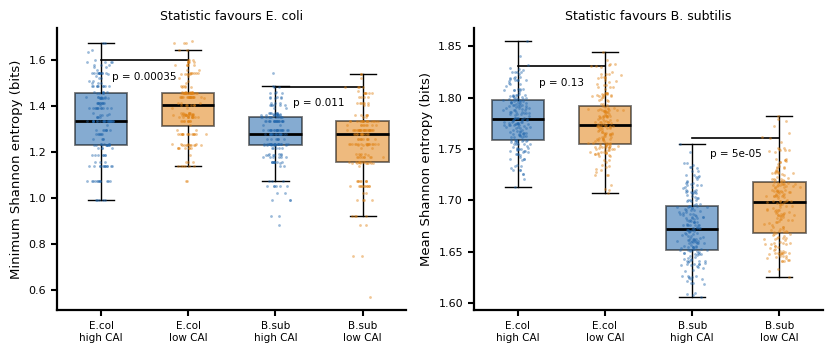

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, stat, nice in zip(axs, ['min', 'mean'],
                          ['Minimum Shannon entropy (bits)', 'Mean Shannon entropy (bits)']):
    data, labels, cols = [], [], []
    for sp in ['ecoli', 'bsubtilis']:
        for grp, col in (('high', C_OK), ('low', '#E08214')):
            data.append(D[f'{sp}_D_{grp}_{stat}'])
            labels.append(f"{SPN[sp].split()[0][0]}.{SPN[sp].split()[1][:3]}\n{grp} CAI")
            cols.append(col)
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, showfliers=False,
                    medianprops=dict(color='k', lw=2))
    for patch, col in zip(bp['boxes'], cols):
        patch.set_facecolor(col); patch.set_alpha(0.55); patch.set_linewidth(1.3)
    for i, v in enumerate(data):
        ax.scatter(np.random.default_rng(i).normal(i + 1, 0.07, len(v)), v,
                   s=4, color=cols[i], alpha=0.45, linewidths=0, zorder=3)
    ax.set_xticklabels(labels, fontsize=7.5)
    ax.set_ylabel(nice)
    for gi, sp in enumerate(['ecoli', 'bsubtilis']):
        p = float(D[f'{sp}_D_{stat}_p'])
        y = max(np.percentile(data[2 * gi], 97), np.percentile(data[2 * gi + 1], 97))
        ax.plot([2 * gi + 1, 2 * gi + 2], [y, y], color='k', lw=1.2)
        ax.text(2 * gi + 1.5, y, f'\np = {p:.2g}', ha='center', va='top', fontsize=7.5)
axs[0].set_title('Statistic favours E. coli', fontsize=9)
axs[1].set_title('Statistic favours B. subtilis', fontsize=9)
plt.tight_layout()
for ext in ('pdf', 'png'):
    for out in (RESULTS, FIGURES):
        fig.savefig(os.path.join(out, f'cds_prompted_supp_cai.{ext}'), dpi=400, bbox_inches='tight')
print('wrote cds_prompted_supp_cai.{pdf,png}')
plt.show()